# COU 07506 Digital Signal Processing
## Week 2: Sampling, Aliasing and Quantization

**Name:** IBRAHIM KELVIN SHIJA
**Registration Number:** 240242495885
**Date:** 21/11/2026


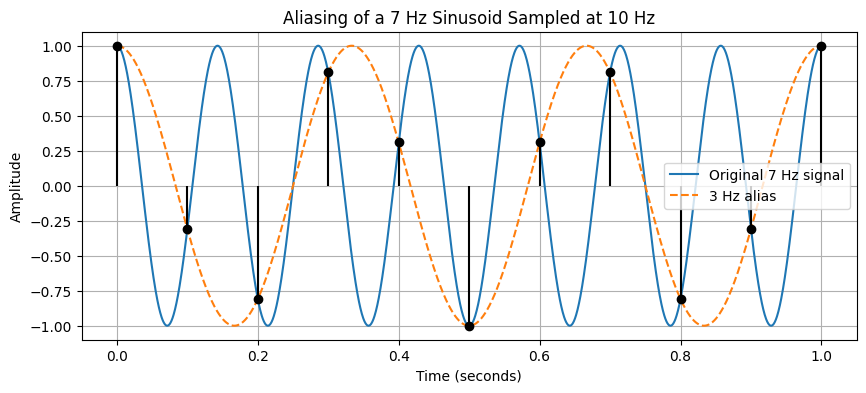

Original frequency: 7.0 Hz
Sampling frequency: 10.0 Hz
Nyquist frequency: 5.0 Hz
Alias frequency: 3.0 Hz


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Original signal parameters
f0 = 7.0
fs = 10.0

# Dense time vector (original signal)
t = np.linspace(0, 1, 2000)

# Sampling points
n = np.arange(0, int(fs) + 1)
tn = n / fs

# Calculate alias frequency
f_alias = abs(f0 - fs * round(f0 / fs))

# Original continuous-looking signal
x = np.cos(2 * np.pi * f0 * t)

# Aliased signal
x_alias = np.cos(2 * np.pi * f_alias * t)

# Plot
plt.figure(figsize=(10, 4))

plt.plot(t, x, label="Original 7 Hz signal")
plt.plot(t, x_alias, "--", label="3 Hz alias")

plt.stem(
    tn,
    np.cos(2 * np.pi * f0 * tn),
    linefmt="k-",
    markerfmt="ko",
    basefmt=" "
)

plt.title("Aliasing of a 7 Hz Sinusoid Sampled at 10 Hz")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Nyquist frequency:", fs / 2, "Hz")
print("Alias frequency:", f_alias, "Hz")

### Results and Discussion — Task 2.1

The original sinusoidal signal had a frequency of 7 Hz and was sampled at 10 Hz.

The Nyquist frequency was calculated as 5 Hz. Since the original frequency was higher than the Nyquist frequency, aliasing occurred.

The observed alias frequency was 3 Hz.

The sampled points of the original 7 Hz signal coincided with those of the 3 Hz alias signal. This demonstrates that insufficient sampling can cause a high-frequency signal to appear as a lower-frequency signal.

ALIASING RESULTS
----------------
fs = 12 Hz | Nyquist = 6.0 Hz | Alias = 5.0 Hz
fs = 14 Hz | Nyquist = 7.0 Hz | Alias = 7.0 Hz
fs = 20 Hz | Nyquist = 10.0 Hz | Alias = 7.0 Hz


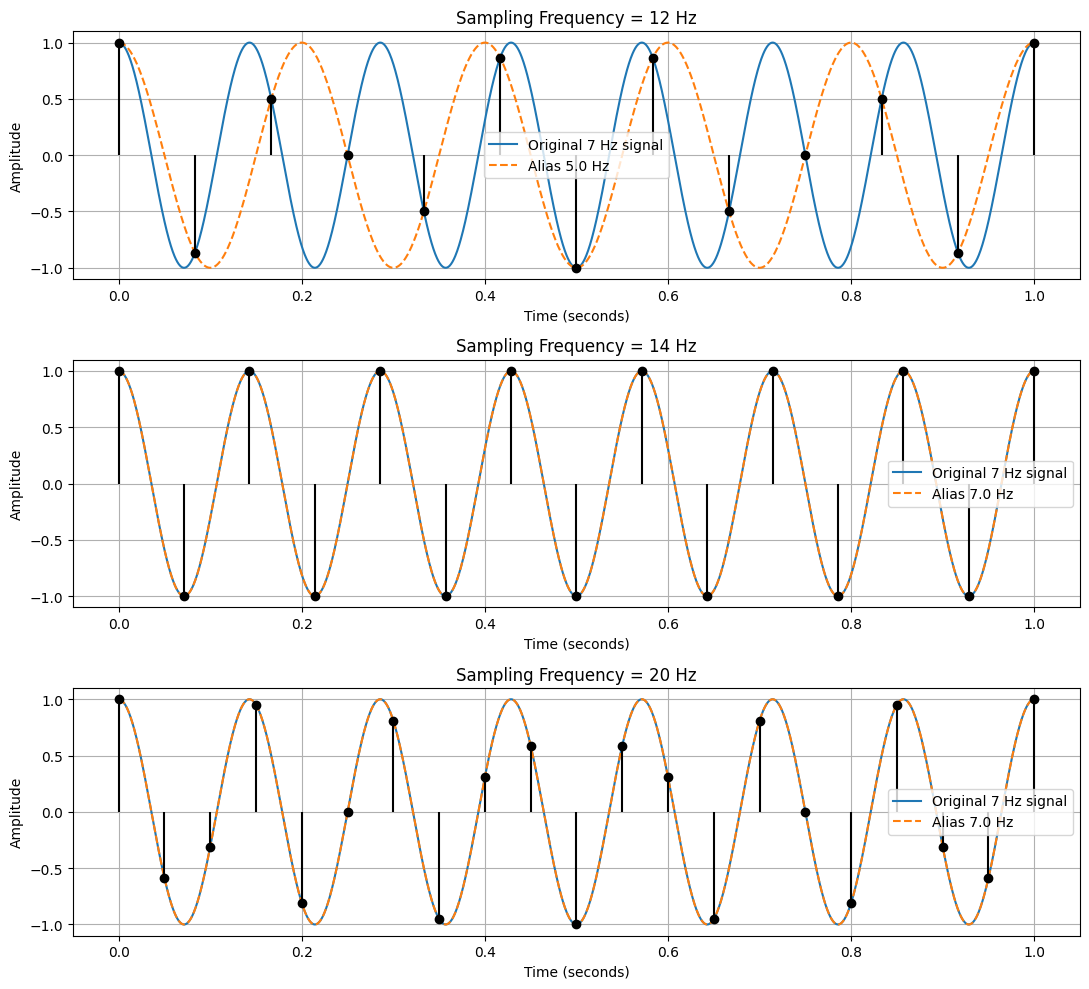

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Original signal frequency
f0 = 7.0

# Different sampling frequencies
sampling_rates = [12, 14, 20]

# Dense time vector
t = np.linspace(0, 1, 2000)

# Original signal
x = np.cos(2 * np.pi * f0 * t)

# Plot original and sampled signals
fig, axes = plt.subplots(3, 1, figsize=(11, 10))

print("ALIASING RESULTS")
print("----------------")

for ax, fs in zip(axes, sampling_rates):

    # Sampling points
    n = np.arange(0, fs + 1)
    tn = n / fs

    # Select integer k to fold frequency into Nyquist range
    k = int(np.floor(f0 / fs + 0.5))

    # Calculate alias frequency
    f_alias = abs(f0 - k * fs)

    # Generate alias signal
    x_alias = np.cos(2 * np.pi * f_alias * t)

    # Plot
    ax.plot(t, x, label="Original 7 Hz signal")
    ax.plot(t, x_alias, "--", label=f"Alias {f_alias:.1f} Hz")

    ax.stem(
        tn,
        np.cos(2 * np.pi * f0 * tn),
        linefmt="k-",
        markerfmt="ko",
        basefmt=" "
    )

    ax.set_title(f"Sampling Frequency = {fs} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

    print(f"fs = {fs} Hz | Nyquist = {fs/2} Hz | Alias = {f_alias} Hz")

plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
import numpy as np

# Original signal frequency
f0 = 7.0

# Sampling frequencies
sampling_rates = [10, 12, 14, 20]

results = []

for fs in sampling_rates:

    # Nyquist frequency
    nyquist = fs / 2

    # Calculate alias frequency
    k = int(np.floor(f0 / fs + 0.5))
    f_alias = abs(f0 - k * fs)

    # Determine sampling condition
    if f0 < nyquist:
        condition = "No aliasing"
    elif f0 == nyquist:
        condition = "Nyquist limit"
    else:
        condition = "Aliasing"

    results.append({
        "Original Frequency (Hz)": f0,
        "Sampling Frequency (Hz)": fs,
        "Nyquist Frequency (Hz)": nyquist,
        "Alias Frequency (Hz)": f_alias,
        "Observation": condition
    })

# Display results
df = pd.DataFrame(results)
display(df)

,Original Frequency (Hz),Sampling Frequency (Hz),Nyquist Frequency (Hz),Alias Frequency (Hz),Observation
0,7.0,10,5.0,3.0,Aliasing
1,7.0,12,6.0,5.0,Aliasing
2,7.0,14,7.0,7.0,Nyquist limit
3,7.0,20,10.0,7.0,No aliasing


### Alias Frequency Results and Discussion

The experiment was repeated using sampling frequencies of 10 Hz,
12 Hz, 14 Hz and 20 Hz.

The results show that the alias frequency depends on the sampling
frequency.

At 10 Hz, the 7 Hz signal appeared as 3 Hz.
At 12 Hz, it appeared as 5 Hz.
At 14 Hz, it was exactly at the Nyquist frequency.
At 20 Hz, the original 7 Hz frequency was below the Nyquist limit,
so no aliasing occurred.

The experimental results agree with the alias-frequency formula.

In [6]:
!pip install pydub

In [8]:
import os

print("Current directory:", os.getcwd())
print("Files available:", os.listdir())

Current directory: /content
Files available: ['.config', 'sample_data']


In [9]:
from google.colab import files

uploaded = files.upload()

Saving Recording.m4a to Recording.m4a


In [10]:
from pydub import AudioSegment

audio = AudioSegment.from_file(
    "Recording.m4a",
    format="m4a"
)

audio = audio.set_channels(1)
audio = audio.set_frame_rate(48000)

audio.export("Recording.wav", format="wav")

print("Audio converted successfully!")

Audio converted successfully!


In [11]:
from scipy.io import wavfile

fs, x = wavfile.read("Recording.wav")

print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(x))
print("Duration:", len(x) / fs, "seconds")

Sampling frequency: 48000 Hz
Number of samples: 179200
Duration: 3.7333333333333334 seconds


In [12]:
import numpy as np
from scipy import signal
from IPython.display import Audio, display
from scipy.io import wavfile

fs, x = wavfile.read("Recording.wav")

# Convert to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize safely
x = x.astype(float)
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

print("Ready for downsampling!")

Ready for downsampling!


In [13]:
for k in [2, 4, 8]:

    # Naive downsampling: no anti-aliasing filter
    naive = x[::k]

    # Proper downsampling: apply FIR anti-aliasing filter
    proper = signal.decimate(x, k, ftype="fir")

    # New sampling frequency
    new_fs = fs // k

    print(f"\nDownsampling factor: {k}")
    print(f"New sampling frequency: {new_fs} Hz")

    print("Naive downsampling:")
    display(Audio(naive, rate=new_fs))

    print("Filtered downsampling:")
    display(Audio(proper, rate=new_fs))


Downsampling factor: 2
New sampling frequency: 24000 Hz
Naive downsampling:


Filtered downsampling:



Downsampling factor: 4
New sampling frequency: 12000 Hz
Naive downsampling:


Filtered downsampling:



Downsampling factor: 8
New sampling frequency: 6000 Hz
Naive downsampling:


Filtered downsampling:


### Listening Observations and Discussion — Task 2.2

The voice recording was downsampled using factors of 2, 4 and 8.

Two methods were compared: naive downsampling without filtering and proper downsampling using an FIR anti-aliasing filter.

The naive version sounded more distorted, while the filtered version sounded clearer.

This difference occurs because naive downsampling does not remove high-frequency components before reducing the sampling rate. These components can cause aliasing.

The FIR anti-aliasing filter suppresses frequencies above the new Nyquist frequency before downsampling, thereby reducing aliasing.

Therefore, anti-aliasing filtering is important when reducing the sampling rate of an audio signal.

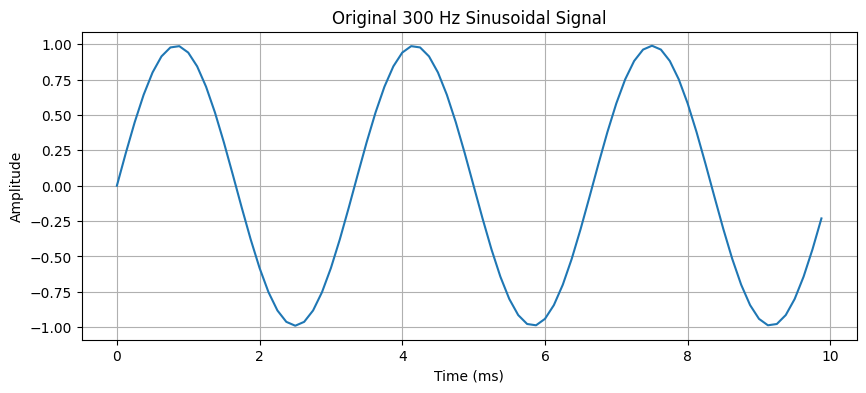

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Sampling frequency
fs = 8000

# Time vector
t = np.arange(0, 0.01, 1/fs)

# Generate a 300 Hz sinusoidal signal
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Plot original signal
plt.figure(figsize=(10, 4))
plt.plot(t * 1e3, x)

plt.title("Original 300 Hz Sinusoidal Signal")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

In [15]:
def quantize(x, bits, full_scale=1.0):

    # Calculate quantization step size
    delta = 2 * full_scale / 2**bits

    # Quantize the signal
    q = np.round(x / delta) * delta

    # Limit values to the quantizer range
    return np.clip(q, -full_scale, full_scale - delta)

In [16]:
xq = quantize(x, 3)

print("Original samples:", x[:10])
print("Quantized samples:", xq[:10])
print("Quantization step size:", 2 / 2**3)

Original samples: [0.         0.23111091 0.44945059 0.64295357 0.80092682 0.91464074
 0.97781146 0.98694816 0.94154595 0.84411376]
Quantized samples: [0.   0.25 0.5  0.75 0.75 0.75 0.75 0.75 0.75 0.75]
Quantization step size: 0.25


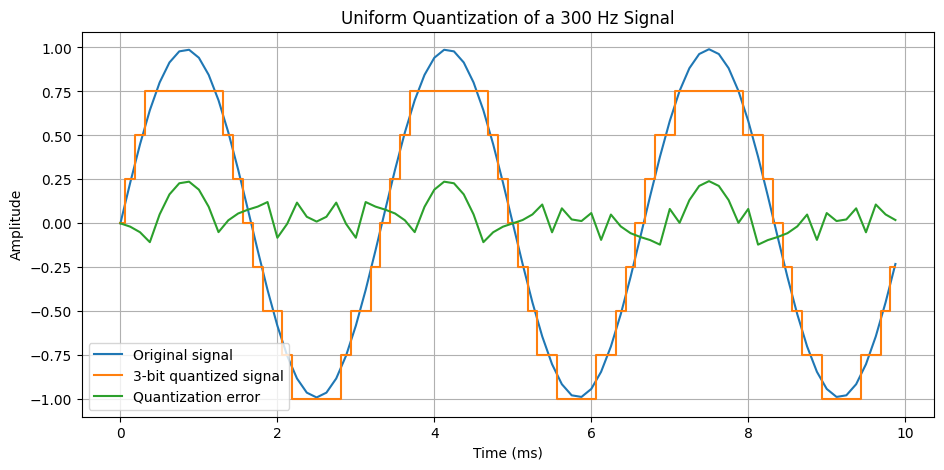

In [17]:
plt.figure(figsize=(11, 5))

plt.plot(t * 1e3, x, label="Original signal")
plt.step(t * 1e3, xq, where="mid", label="3-bit quantized signal")
plt.plot(t * 1e3, x - xq, label="Quantization error")

plt.title("Uniform Quantization of a 300 Hz Signal")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

### Results and Discussion — Task 2.3

A 300 Hz sinusoidal signal was generated with a sampling frequency
of 8000 Hz and an amplitude of 0.99.

A 3-bit uniform quantizer was implemented, providing 8 quantization
levels.

The calculated quantization step size was 0.25 V.

The plot shows that the original sinusoidal signal is smooth, while
the quantized signal has a staircase shape due to the limited
number of available amplitude levels.

The quantization error is the difference between the original
signal and the quantized signal.

This experiment demonstrates how quantization introduces an error
when representing continuous amplitude values digitally.

In [18]:
# Number of bits to test
bits = np.arange(2, 17, 2)

# Store measured SQNR values
meas = []

# Calculate measured SQNR for each bit depth
for B in bits:

    # Quantize the original signal
    xq = quantize(x, B)

    # Calculate quantization error
    e = x - xq

    # Calculate measured SQNR
    sqnr = 10 * np.log10(
        np.sum(x**2) / np.sum(e**2)
    )

    meas.append(sqnr)

# Calculate theoretical SQNR
theoretical = 6.02 * bits + 1.76

print("Bits:", bits)
print("Measured SQNR:", np.round(meas, 2))
print("Theoretical SQNR:", np.round(theoretical, 2))

Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [ 9.6  23.58 36.81 48.93 62.81 72.84 88.13 98.91]
Theoretical SQNR: [13.8  25.84 37.88 49.92 61.96 74.   86.04 98.08]


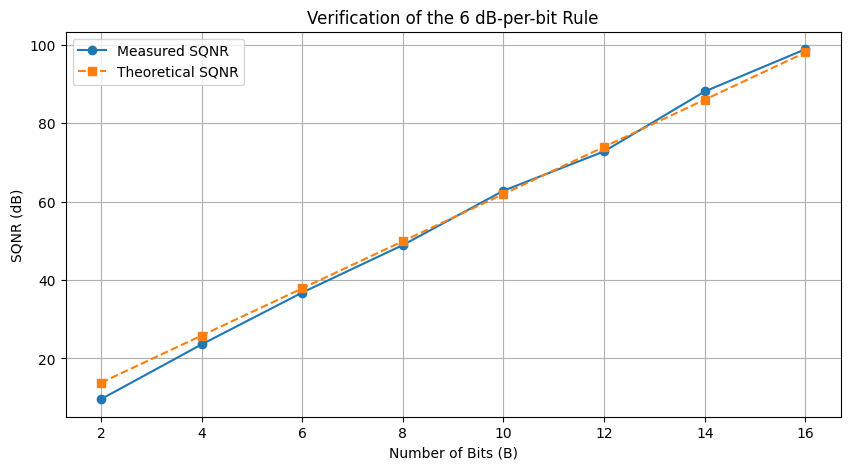

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theoretical, "s--", label="Theoretical SQNR")

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")

plt.xticks(bits)
plt.legend()
plt.grid(True)

plt.show()

### Results and Discussion — Task 2.4

The SQNR was measured for bit depths ranging from 2 to 16 bits
in increments of 2 bits.

The results showed that SQNR generally increases as the number
of quantization bits increases.

For example, the measured SQNR increased from 9.60 dB at
2 bits to 23.58 dB at 4 bits.

The theoretical SQNR increases by approximately 6.02 dB
for every additional bit. Therefore, adding two bits should
increase SQNR by approximately 12.04 dB.

The measured results followed this general trend, although
they were not exactly equal to the theoretical values.

The differences occur because the theoretical formula assumes
ideal quantization conditions, while the experiment uses a
finite number of samples and actual quantization errors.

Therefore, the experiment generally verifies the
6 dB-per-bit rule.

In [20]:
# Quantize the voice recording
voice_4bit = quantize(x, 4)
voice_8bit = quantize(x, 8)
voice_12bit = quantize(x, 12)

print("Voice quantization completed!")

Voice quantization completed!


In [21]:
bits_list = [4, 8, 12]

quantized_signals = {
    4: voice_4bit,
    8: voice_8bit,
    12: voice_12bit
}

voice_sqnr = {}

for B in bits_list:

    xq = quantized_signals[B]

    error = x - xq

    sqnr = 10 * np.log10(
        np.sum(x**2) / np.sum(error**2)
    )

    voice_sqnr[B] = sqnr

    print(f"{B}-bit SQNR: {sqnr:.2f} dB")

4-bit SQNR: 23.58 dB
8-bit SQNR: 48.93 dB
12-bit SQNR: 72.84 dB


In [22]:
from IPython.display import Audio, display

print("Original voice:")
display(Audio(x, rate=fs))

print("4-bit quantized voice:")
display(Audio(voice_4bit, rate=fs))

print("8-bit quantized voice:")
display(Audio(voice_8bit, rate=fs))

print("12-bit quantized voice:")
display(Audio(voice_12bit, rate=fs))

Original voice:


4-bit quantized voice:


8-bit quantized voice:


12-bit quantized voice:


In [23]:
import os

print(os.listdir("/content"))

['.config', 'Recording.m4a', 'Recording.wav', 'sample_data']


In [24]:
from scipy.io import wavfile
import numpy as np

fs_voice, voice = wavfile.read("Recording.wav")

if voice.ndim > 1:
    voice = voice.mean(axis=1)

voice = voice.astype(float)

peak = np.max(np.abs(voice))
if peak > 0:
    voice = voice / peak

print("Sampling frequency:", fs_voice)
print("Number of samples:", len(voice))
print("Duration:", len(voice) / fs_voice)

Sampling frequency: 48000
Number of samples: 179200
Duration: 3.7333333333333334


In [25]:
from IPython.display import Audio, display

display(Audio(voice, rate=fs_voice))

In [26]:
# Quantize the original voice recording
voice_4bit = quantize(voice, 4)
voice_8bit = quantize(voice, 8)
voice_12bit = quantize(voice, 12)

print("Voice quantization completed!")

Voice quantization completed!


In [27]:
bits_list = [4, 8, 12]

quantized_signals = {
    4: voice_4bit,
    8: voice_8bit,
    12: voice_12bit
}

voice_sqnr = {}

for B in bits_list:
    xq = quantized_signals[B]

    error = voice - xq

    sqnr = 10 * np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    voice_sqnr[B] = sqnr

    print(f"{B}-bit SQNR: {sqnr:.2f} dB")

4-bit SQNR: 16.21 dB
8-bit SQNR: 40.29 dB
12-bit SQNR: 64.36 dB


In [28]:
from IPython.display import Audio, display

print("4-bit voice:")
display(Audio(voice_4bit, rate=fs_voice))

print("8-bit voice:")
display(Audio(voice_8bit, rate=fs_voice))

print("12-bit voice:")
display(Audio(voice_12bit, rate=fs_voice))

4-bit voice:


8-bit voice:


12-bit voice:


In [29]:
import pandas as pd

voice_results = pd.DataFrame({
    "Bit Depth": bits_list,
    "Quantization Levels": [2**B for B in bits_list],
    "Measured SQNR (dB)": [
        round(voice_sqnr[B], 2) for B in bits_list
    ]
})

display(voice_results)

,Bit Depth,Quantization Levels,Measured SQNR (dB)
0,4,16,16.21
1,8,256,40.29
2,12,4096,64.36


### Discussion — Task 2.5

The measured SQNR of speech is generally lower than that
of a full-scale sinusoidal signal with the same number of bits.

This is because speech has varying amplitudes and is not
consistently at full scale. Some speech samples have relatively
small amplitudes, making quantization noise more significant
compared with the signal power.

A full-scale sinusoidal signal uses its available amplitude
range more effectively, resulting in a higher SQNR.

The experiment showed that increasing the bit depth from
4 to 8 and then to 12 bits improved the measured SQNR
from 16.21 dB to 40.29 dB and 64.36 dB, respectively.

### Question 1: Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when fs = 10 Hz.

The sampling frequency is 10 Hz. Therefore, the Nyquist frequency is:

\[
f_N = \frac{f_s}{2} = \frac{10}{2} = 5\,Hz
\]

The original signal frequency is 7 Hz, which is above the Nyquist frequency. Frequencies above the Nyquist frequency cause aliasing and appear as lower frequencies.

The alias frequency is calculated as:

\[
f_{alias}=|f_0-f_s|
\]

\[
f_{alias}=|7-10|=3\,Hz
\]

Therefore, the 7 Hz signal appears as a 3 Hz signal after sampling at 10 Hz.

**Frequency-axis sketch:**

```text
Frequency (Hz)

0       3       5       7       10
|-------|-------|-------|--------|
        3 Hz    Nyquist 7 Hz     fs

        <------->
        Alias frequency
```

This demonstrates that sampling above the Nyquist limit without proper filtering causes aliasing.

### Question 2: In Task 2.2, why can the aliasing heard in the naive version not be removed afterwards?

Aliasing in the naive downsampling method cannot be removed afterwards because the original frequency information is lost during downsampling. Different frequency components may overlap and appear as the same frequency.

Once this happens, it becomes difficult to distinguish the original signal from the aliased components.

Therefore, an anti-aliasing low-pass filter must be applied before downsampling to remove frequencies above the new Nyquist frequency.

### Question 3: By how much does the SQNR change when one bit is added? Does your measurement agree?

The theoretical SQNR increases by approximately 6.02 dB for every additional bit.

The theoretical relationship is:

\[
SQNR = 6.02B + 1.76\,dB
\]

This means that increasing the quantizer resolution by one bit improves the SQNR by approximately 6 dB.

In my experiment, the measured SQNR increased as the number of bits increased. The measured values do not increase by exactly the same amount in every step because of the signal samples and quantization error.

However, the overall trend agrees with the theoretical 6 dB-per-bit rule.

### Question 4: A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.

I would recommend a sampling rate of 10 samples per second (10 Hz).

At a maximum temperature change of 0.1 °C per second, sampling at 10 Hz gives a maximum temperature change of:

\[
\frac{0.1}{10}=0.01\,°C
\]

between consecutive samples. This is suitable for tracking temperature changes at the required resolution.

For the ADC resolution, the temperature range is 0–100 °C, with a required resolution of 0.01 °C.

The number of intervals required is:

\[
N=\frac{100}{0.01}=10000
\]

The number of bits required is:

\[
B=\lceil\log_2(10001)\rceil=14
\]

Therefore, a 14-bit ADC is recommended because it provides 16,384 quantization levels, which is sufficient to represent the required temperature resolution.

**Conclusion:** A sampling rate of 10 Hz and a 14-bit ADC are recommended for this temperature monitoring application.

### AI-Use Statement

I used ChatGPT to help explain Digital Signal Processing concepts, understand Python code, and troubleshoot errors during the laboratory activities. I executed the code in Google Colab, examined the generated plots and numerical results, and listened to the audio outputs to verify the results. I reviewed the explanations to ensure that I understand the code and the concepts used in this laboratory.